In [30]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal

print("Installations Working!")

Installations Working!


## Instructor Provide Code

In [31]:
import numpy as np
import matplotlib.pyplot as plt

def hw2q2(seed=None):
    if seed is not None:                       # FIX: optional reproducibility
        np.random.seed(seed)

    Ntrain = 100
    data = generateData(Ntrain)
    plot3(data[0,:], data[1,:], data[2,:], title='Training Dataset')
    xTrain = data[0:2,:]
    yTrain = data[2,:]

    Nvalidate = 1000
    data = generateData(Nvalidate)
    plot3(data[0,:], data[1,:], data[2,:], title='Validation Dataset')   # FIX: title
    xValidate = data[0:2,:]
    yValidate = data[2,:]

    return xTrain, yTrain, xValidate, yValidate

def generateData(N):
    gmmParameters = {}
    gmmParameters['priors'] = [.3, .4, .3]
    gmmParameters['meanVectors'] = np.array([[-10, 0, 10], [0, 0, 0], [10, 0, -10]])
    gmmParameters['covMatrices'] = np.zeros((3, 3, 3))
    gmmParameters['covMatrices'][:,:,0] = np.array([[1, 0, -3], [0, 1, 0], [-3, 0, 15]])
    gmmParameters['covMatrices'][:,:,1] = np.array([[8, 0, 0], [0, .5, 0], [0, 0, .5]])
    gmmParameters['covMatrices'][:,:,2] = np.array([[1, 0, -3], [0, 1, 0], [-3, 0, 15]])
    x, labels = generateDataFromGMM(N, gmmParameters)
    return x

def generateDataFromGMM(N, gmmParameters):
    priors = gmmParameters['priors']
    meanVectors = gmmParameters['meanVectors']
    covMatrices = gmmParameters['covMatrices']
    n = meanVectors.shape[0]
    C = len(priors)
    x = np.zeros((n, N))
    labels = np.zeros((1, N))
    u = np.random.random((1, N))
    thresholds = np.zeros((1, C+1))
    thresholds[:, 0:C] = np.cumsum(priors)
    thresholds[:, C] = 1
    for l in range(C):
        indl = np.where(u <= thresholds[0, l])          # FIX: was float(thresholds[:,l])
        Nl = len(indl[1])
        labels[indl] = (l+1)*1
        u[indl] = 1.1
        x[:, indl[1]] = np.transpose(np.random.multivariate_normal(meanVectors[:,l], covMatrices[:,:,l], Nl))
    return x, labels

def plot3(a, b, c, mark="o", col="b", title="Dataset"):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')               # FIX: was Axes3D(fig)
    ax.scatter(a, b, c, marker=mark, color=col)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")
    ax.set_title(title)
    plt.show()

In [32]:

def z_cubic(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(X)), x1, x2, x1**2, x1*x2, x2**2, x1**3, x1**2*x2, x1*x2**2, x2**3])

def nll(w, Z, l):
    a = Z @ w
    return np.mean(l * np.logaddexp(0, -a) + (1 - l) * np.logaddexp(0, a))



def ml_opt(w, Z_train, y_Train):
    res = scipy.optimize.minimize(ml_objective, w, args=(Z_train, y_Train))
    print(res.success, res.message)
    return res.x

def map_opt(w, Z_train, y_Train, gamma, sigma2):
    res = scipy.optimize.minimize(map_objective, w, args=(Z_train, y_Train, gamma, sigma2))
    print(res.success, res.message)
    return res.x


def ml_objective(w, Z, y):
    r = y - Z @ w
    return np.mean(r**2) 

def map_objective(w, Z, y, gamma, sigma2):
    r = y - Z @ w 
    return np.mean(r**2) + (sigma2 / (len(y) * gamma)) * np.sum(w**2)

def avg_sq_error(Z_val, y_val, w):
    return np.mean(ml_objective(w, Z_val, y_val))


### Maximum Likelihood Estimate


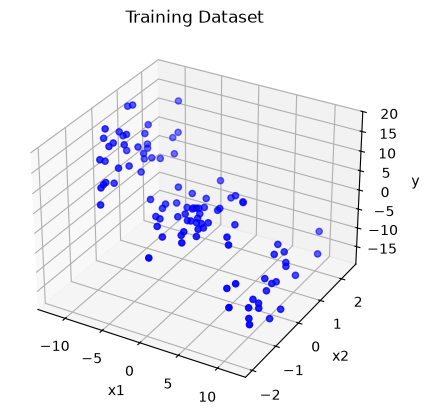

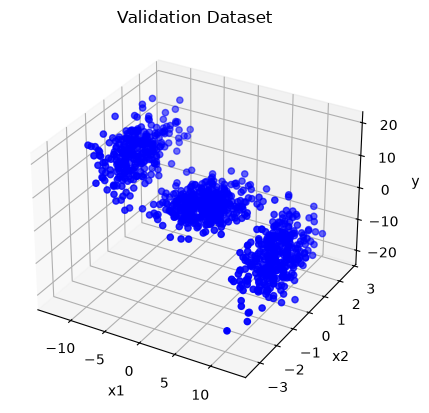

[-2.20509238e-01  9.48025269e-02 -2.59613296e-01  4.61793186e-04
  2.21569558e-02  1.07778853e-01 -1.10827733e-02 -1.18336052e-03
 -1.09380604e-04  6.12528003e-02]
(10,)


In [40]:
xTrain, yTrain, xValidate, yValidate = hw2q2(0)

X_train = xTrain.T        # (100, 2)
X_val   = xValidate.T     # (1000, 2)

Z_train = z_cubic(X_train)
Z_val   = z_cubic(X_val)


# ML closed form: solve (Z^T Z) w = Z^T y
# Learned From Prof Ionondus's Class
w_ML_der = np.linalg.solve(Z_train.T @ Z_train, Z_train.T @ yTrain)

print(w_ML_der)
print(w_ML_der.shape)   # (10,)

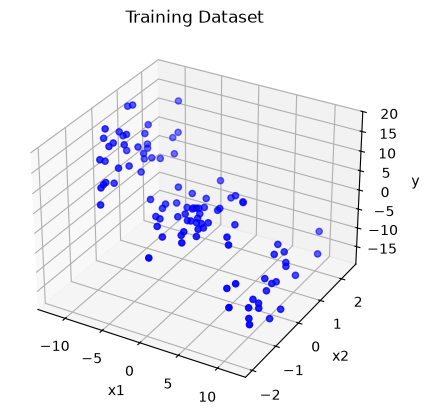

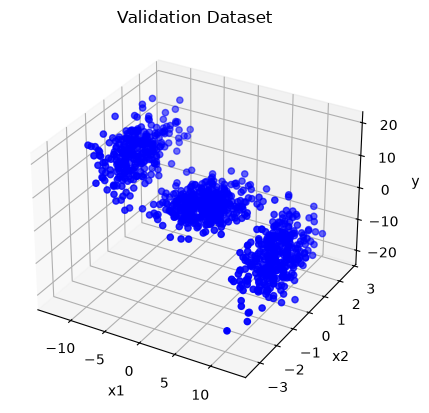

Estimated sigma^2 (ML):        2.8466
ML   validation error:         4.0660
MAP  best gamma:               1.70e-06  (lambda = 1.67e+06)
MAP  best validation error:    3.8799
MAP  error at gamma = 1e8:     4.0660   (should equal ML)
MAP  error at gamma = 1e-15:   71.7569   (predict-zero ref: 71.7569)

   term |       w_ML | w_MAP (best)
      1 |    -0.2205 |     -0.00001
     x1 |     0.0948 |     -0.00007
     x2 |    -0.2596 |     -0.00001
    x1² |     0.0005 |     -0.00032
   x1x2 |     0.0222 |      0.00005
    x2² |     0.1078 |     -0.00000
    x1³ |    -0.0111 |     -0.00982
  x1²x2 |    -0.0012 |     -0.00017
  x1x2² |    -0.0001 |     -0.00001
    x2³ |     0.0613 |     -0.00000


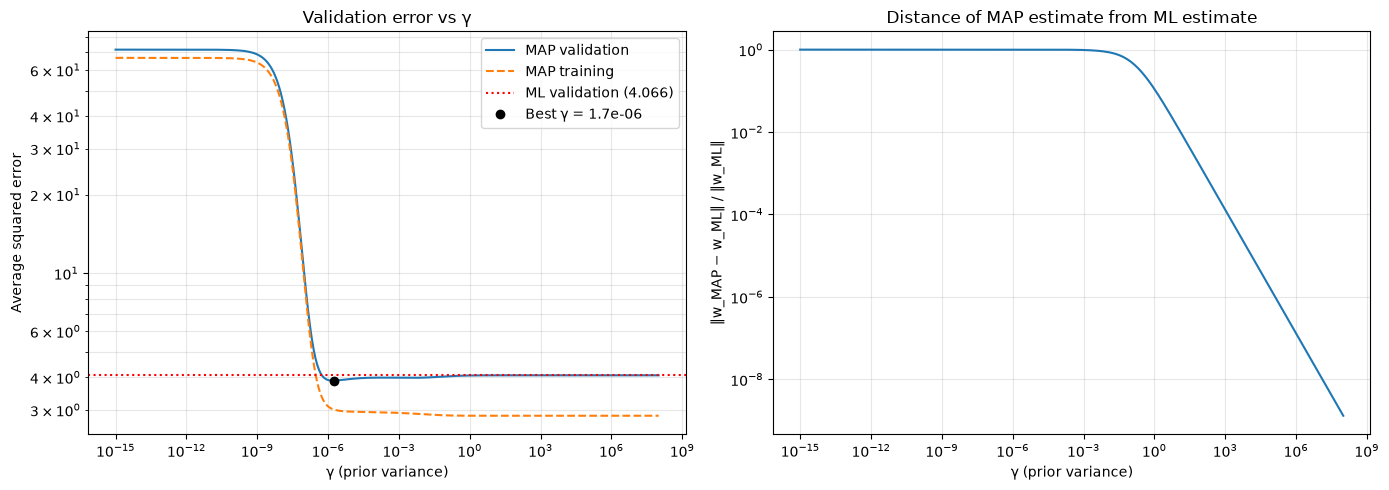

In [48]:
import numpy as np
import matplotlib.pyplot as plt

def z_cubic(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([np.ones(len(X)), x1, x2, x1**2, x1*x2, x2**2,
                            x1**3, x1**2*x2, x1*x2**2, x2**3])

def fit(Z, y, lam=0.0):
    """Solves (Z^T Z + lam I) w = Z^T y.  lam = 0 -> ML;  lam = sigma2/gamma -> MAP."""
    return np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ y)

def mse(Z, y, w):
    return np.mean((y - Z @ w)**2)

# ---------------- Data ----------------
xTrain, yTrain, xValidate, yValidate = hw2q2(0)
Z_tr, Z_val = z_cubic(xTrain.T), z_cubic(xValidate.T)

# ---------------- ML ----------------
w_ML   = fit(Z_tr, yTrain)
sigma2 = mse(Z_tr, yTrain, w_ML)            # ML estimate of noise variance
err_ML = mse(Z_val, yValidate, w_ML)

# Cross-check against NumPy's least-squares solver
assert np.allclose(w_ML, np.linalg.lstsq(Z_tr, yTrain, rcond=None)[0])

# ---------------- MAP sweep ----------------
m, n = 15, 8
gammas = np.logspace(-m, n, 300)
W_MAP  = np.array([fit(Z_tr, yTrain, sigma2 / g) for g in gammas])
val_err   = np.array([mse(Z_val, yValidate, w) for w in W_MAP])
train_err = np.array([mse(Z_tr,  yTrain,    w) for w in W_MAP])
rel_dist  = np.linalg.norm(W_MAP - w_ML, axis=1) / np.linalg.norm(w_ML)   # how far MAP is from ML

best = np.argmin(val_err)

# ---------------- Summary ----------------
print(f"Estimated sigma^2 (ML):        {sigma2:.4f}")
print(f"ML   validation error:         {err_ML:.4f}")
print(f"MAP  best gamma:               {gammas[best]:.2e}  (lambda = {sigma2/gammas[best]:.2e})")
print(f"MAP  best validation error:    {val_err[best]:.4f}")
print(f"MAP  error at gamma = 1e{n}:     {val_err[-1]:.4f}   (should equal ML)")
print(f"MAP  error at gamma = 1e-{m}:   {val_err[0]:.4f}   (predict-zero ref: {np.mean(yValidate**2):.4f})")

terms = ["1", "x1", "x2", "x1²", "x1x2", "x2²", "x1³", "x1²x2", "x1x2²", "x2³"]
print(f"\n{'term':>7} | {'w_ML':>10} | {'w_MAP (best)':>12}")
for t, a, b in zip(terms, w_ML, W_MAP[best]):
    print(f"{t:>7} | {a:>10.4f} | {b:>12.5f}")

# ---------------- Plots ----------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.semilogx(gammas, val_err, label="MAP validation")
ax1.semilogx(gammas, train_err, '--', label="MAP training")
ax1.axhline(err_ML, color='r', ls=':', label=f"ML validation ({err_ML:.3f})")
ax1.plot(gammas[best], val_err[best], 'ko', label=f"Best γ = {gammas[best]:.1e}")
ax1.set_yscale('log')
ax1.set_xlabel("γ (prior variance)"); ax1.set_ylabel("Average squared error")
ax1.set_title("Validation error vs γ"); ax1.legend(); ax1.grid(True, which="both", alpha=0.3)

ax2.loglog(gammas, rel_dist)
ax2.set_xlabel("γ (prior variance)"); ax2.set_ylabel("‖w_MAP − w_ML‖ / ‖w_ML‖")
ax2.set_title("Distance of MAP estimate from ML estimate")
ax2.grid(True, which="both", alpha=0.3)

plt.tight_layout(); plt.show()